# Análise de Dados

### Importando as Bibliotecas

In [27]:
import pandas as pd
import numpy as np

import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)

def drop_reset_index(df):
    df = df.dropna()
    df = df.reset_index(drop=True)
    df.index += 1
    return df

### Importando a Base de Dados

In [28]:
df = pd.read_csv('https://github.com/futpythontrader/YouTube/raw/main/Bases_de_Dados/Betfair/Base_de_Dados_Betfair_Exchange_Back_Lay.csv')
# columns = ['Date','League','Home','Away','Season','Goals_H','Goals_A','Odd_H','Odd_D','Odd_A','Odd_Over25','Odd_Under25','Odd_BTTS_Yes','Odd_BTTS_No','Goals_Minutes_Home','Goals_Minutes_Away']
# df = df[columns]
# df = drop_reset_index(df)

In [29]:
df = df[['Date','Time','League','Home','Away','Goals_H','Goals_A','Goals_Min_H','Goals_Min_A',
         'Odd_H_Back','Odd_H_Lay','Odd_A_Back','Odd_A_Lay','Odd_D_Back','Odd_D_Lay',
         'Odd_Over25_FT_Back','Odd_Over25_FT_Lay','Odd_Under25_FT_Back','Odd_Under25_FT_Lay',
         'Odd_BTTS_Yes_Back','Odd_BTTS_Yes_Lay','Odd_BTTS_No_Back','Odd_BTTS_No_Lay',
         'Odd_CS_0x0_Back','Odd_CS_0x0_Lay','Odd_CS_0x1_Back','Odd_CS_0x1_Lay','Odd_CS_1x0_Back','Odd_CS_1x0_Lay']]
df.columns = ['Date','Time','League','Home','Away','Goals_H','Goals_A','Goals_Min_H','Goals_Min_A',
              'Odd_H','Odd_H_Lay','Odd_A','Odd_A_Lay','Odd_D','Odd_D_Lay',
              'Odd_Over25','Odd_Over25_FT_Lay','Odd_Under25','Odd_Under25_FT_Lay',
              'Odd_BTTS_Yes','Odd_BTTS_Yes_Lay','Odd_BTTS_No','Odd_BTTS_No_Lay',
              'Odd_CS_0x0_Back','Odd_0x0','Odd_CS_0x1_Back','Odd_0x1','Odd_CS_1x0_Back','Odd_1x0']

### Análise Exploratória dos Dados

In [30]:
df.head()

,Date,Time,League,Home,Away,Goals_H,Goals_A,Goals_Min_H,Goals_Min_A,Odd_H,Odd_H_Lay,Odd_A,Odd_A_Lay,Odd_D,Odd_D_Lay,Odd_Over25,Odd_Over25_FT_Lay,Odd_Under25,Odd_Under25_FT_Lay,Odd_BTTS_Yes,Odd_BTTS_Yes_Lay,Odd_BTTS_No,Odd_BTTS_No_Lay,Odd_CS_0x0_Back,Odd_0x0,Odd_CS_0x1_Back,Odd_0x1,Odd_CS_1x0_Back,Odd_1x0
0,2024-03-16,10:00:00,SPAIN - LALIGA,Mallorca,Granada CF,1,0,[85],[],1.88,1.89,5.30,5.40,3.50,3.55,2.50,2.68,1.60,1.66,2.24,2.38,1.73,1.81,8.4,9.2,13.0,14.0,6.2,6.8
1,2024-03-16,11:00:00,ITALY - SERIE A,Monza,Cagliari,1,0,[41],[],2.12,2.16,3.85,3.95,3.60,3.65,1.99,2.10,1.92,2.02,1.82,1.94,2.06,2.22,12.0,13.5,13.0,14.5,8.6,9.6
2,2024-03-16,11:00:00,ITALY - SERIE A,Udinese,Torino,0,2,[],"[10, 53]",2.98,3.05,2.92,2.94,3.05,3.10,2.70,2.90,1.53,1.59,2.12,2.28,1.79,1.89,7.4,8.0,8.0,8.6,8.0,8.8
3,2024-03-16,12:00:00,ENGLAND - PREMIER LEAGUE,Burnley,Brentford,2,1,"[10, 62]",[83],3.35,3.40,2.26,2.28,3.75,3.80,1.81,1.83,2.20,2.24,1.70,1.73,2.36,2.44,15.5,16.0,11.0,12.0,14.5,15.0
4,2024-03-16,12:00:00,ENGLAND - PREMIER LEAGUE,Luton,Nottingham,1,1,[89],[34],2.88,2.90,2.56,2.58,3.75,3.80,1.71,1.74,2.34,2.40,1.60,1.64,2.58,2.68,17.5,18.5,13.5,14.0,14.5,15.5


In [31]:
df.tail()

,Date,Time,League,Home,Away,Goals_H,Goals_A,Goals_Min_H,Goals_Min_A,Odd_H,Odd_H_Lay,Odd_A,Odd_A_Lay,Odd_D,Odd_D_Lay,Odd_Over25,Odd_Over25_FT_Lay,Odd_Under25,Odd_Under25_FT_Lay,Odd_BTTS_Yes,Odd_BTTS_Yes_Lay,Odd_BTTS_No,Odd_BTTS_No_Lay,Odd_CS_0x0_Back,Odd_0x0,Odd_CS_0x1_Back,Odd_0x1,Odd_CS_1x0_Back,Odd_1x0
6135,2024-06-01,03:00:00,JAPAN - J1 LEAGUE,Machida,Albirex Niigata,1,3,[27],"[24, 45, 52]",1.74,1.78,5.60,5.90,3.80,3.90,2.18,2.24,1.80,1.85,2.08,2.22,1.83,1.93,10.5,12.0,15.5,17.0,6.6,7.4
6136,2024-06-01,03:00:00,JAPAN - J1 LEAGUE,Shonan Bellmare,Gamba Osaka,1,2,[78],"[29, 65]",2.82,2.92,2.76,2.84,3.30,3.40,2.12,2.24,1.81,1.90,1.86,1.93,2.08,2.18,10.5,12.0,9.8,11.0,10.0,11.0
6137,2024-06-01,04:00:00,JAPAN - J1 LEAGUE,Urawa Reds,Vissel Kobe,1,1,[61],[16],3.15,3.25,2.46,2.50,3.45,3.55,2.06,2.14,1.87,1.95,1.84,1.93,2.08,2.20,11.0,12.5,9.4,10.5,11.0,12.0
6138,2024-06-01,07:00:00,JAPAN - J1 LEAGUE,Kyoto,Cerezo Osaka,1,1,[55],[33],4.00,4.20,2.10,2.12,3.50,3.55,2.14,2.24,1.80,1.87,1.93,2.04,1.97,2.08,10.5,11.5,8.0,8.6,12.5,14.0
6139,2024-06-01,08:30:00,ESTONIA - MEISTRILIIGA,Flora,Paide,2,0,"[15, 32]",[],2.62,3.20,2.38,2.86,3.40,4.90,1.68,1.89,2.12,2.70,1.58,1.78,2.28,2.76,3.7,22.0,3.5,16.5,3.5,17.5


In [32]:
display(df)

,Date,Time,League,Home,Away,Goals_H,Goals_A,Goals_Min_H,Goals_Min_A,Odd_H,Odd_H_Lay,Odd_A,Odd_A_Lay,Odd_D,Odd_D_Lay,Odd_Over25,Odd_Over25_FT_Lay,Odd_Under25,Odd_Under25_FT_Lay,Odd_BTTS_Yes,Odd_BTTS_Yes_Lay,Odd_BTTS_No,Odd_BTTS_No_Lay,Odd_CS_0x0_Back,Odd_0x0,Odd_CS_0x1_Back,Odd_0x1,Odd_CS_1x0_Back,Odd_1x0
0,2024-03-16,10:00:00,SPAIN - LALIGA,Mallorca,Granada CF,1,0,[85],[],1.88,1.89,5.30,5.40,3.50,3.55,2.50,2.68,1.60,1.66,2.24,2.38,1.73,1.81,8.4,9.2,13.0,14.0,6.2,6.8
1,2024-03-16,11:00:00,ITALY - SERIE A,Monza,Cagliari,1,0,[41],[],2.12,2.16,3.85,3.95,3.60,3.65,1.99,2.10,1.92,2.02,1.82,1.94,2.06,2.22,12.0,13.5,13.0,14.5,8.6,9.6
2,2024-03-16,11:00:00,ITALY - SERIE A,Udinese,Torino,0,2,[],"[10, 53]",2.98,3.05,2.92,2.94,3.05,3.10,2.70,2.90,1.53,1.59,2.12,2.28,1.79,1.89,7.4,8.0,8.0,8.6,8.0,8.8
3,2024-03-16,12:00:00,ENGLAND - PREMIER LEAGUE,Burnley,Brentford,2,1,"[10, 62]",[83],3.35,3.40,2.26,2.28,3.75,3.80,1.81,1.83,2.20,2.24,1.70,1.73,2.36,2.44,15.5,16.0,11.0,12.0,14.5,15.0
4,2024-03-16,12:00:00,ENGLAND - PREMIER LEAGUE,Luton,Nottingham,1,1,[89],[34],2.88,2.90,2.56,2.58,3.75,3.80,1.71,1.74,2.34,2.40,1.60,1.64,2.58,2.68,17.5,18.5,13.5,14.0,14.5,15.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6135,2024-06-01,03:00:00,JAPAN - J1 LEAGUE,Machida,Albirex Niigata,1,3,[27],"[24, 45, 52]",1.74,1.78,5.60,5.90,3.80,3.90,2.18,2.24,1.80,1.85,2.08,2.22,1.83,1.93,10.5,12.0,15.5,17.0,6.6,7.4
6136,2024-06-01,03:00:00,JAPAN - J1 LEAGUE,Shonan Bellmare,Gamba Osaka,1,2,[78],"[29, 65]",2.82,2.92,2.76,2.84,3.30,3.40,2.12,2.24,1.81,1.90,1.86,1.93,2.08,2.18,10.5,12.0,9.8,11.0,10.0,11.0
6137,2024-06-01,04:00:00,JAPAN - J1 LEAGUE,Urawa Reds,Vissel Kobe,1,1,[61],[16],3.15,3.25,2.46,2.50,3.45,3.55,2.06,2.14,1.87,1.95,1.84,1.93,2.08,2.20,11.0,12.5,9.4,10.5,11.0,12.0
6138,2024-06-01,07:00:00,JAPAN - J1 LEAGUE,Kyoto,Cerezo Osaka,1,1,[55],[33],4.00,4.20,2.10,2.12,3.50,3.55,2.14,2.24,1.80,1.87,1.93,2.04,1.97,2.08,10.5,11.5,8.0,8.6,12.5,14.0


In [33]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6140 entries, 0 to 6139
Data columns (total 29 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Date                6140 non-null   object 
 1   Time                6140 non-null   object 
 2   League              6140 non-null   object 
 3   Home                6140 non-null   object 
 4   Away                6140 non-null   object 
 5   Goals_H             6140 non-null   int64  
 6   Goals_A             6140 non-null   int64  
 7   Goals_Min_H         6140 non-null   object 
 8   Goals_Min_A         6140 non-null   object 
 9   Odd_H               6140 non-null   float64
 10  Odd_H_Lay           6140 non-null   float64
 11  Odd_A               6140 non-null   float64
 12  Odd_A_Lay           6140 non-null   float64
 13  Odd_D               6140 non-null   float64
 14  Odd_D_Lay           6140 non-null   float64
 15  Odd_Over25          6140 non-null   float64
 16  Odd_Ov

In [34]:
df.describe()

,Goals_H,Goals_A,Odd_H,Odd_H_Lay,Odd_A,Odd_A_Lay,Odd_D,Odd_D_Lay,Odd_Over25,Odd_Over25_FT_Lay,Odd_Under25,Odd_Under25_FT_Lay,Odd_BTTS_Yes,Odd_BTTS_Yes_Lay,Odd_BTTS_No,Odd_BTTS_No_Lay,Odd_CS_0x0_Back,Odd_0x0,Odd_CS_0x1_Back,Odd_0x1,Odd_CS_1x0_Back,Odd_1x0
count,6140.000000,6140.000000,6140.000000,6140.000000,6140.000000,6140.000000,6140.000000,6140.000000,6140.000000,6140.000000,6140.000000,6140.000000,6140.000000,6140.000000,6140.000000,6140.000000,6140.000000,6140.000000,6140.000000,6140.000000,6140.000000,6140.000000
mean,1.500651,1.205537,2.540355,57.258451,3.909866,85.240700,3.630238,61.613235,1.863259,4.266741,1.919349,43.292619,1.699062,147.804787,1.862779,148.941863,9.993469,280.986384,9.824521,294.139316,8.006834,260.559528
std,1.295990,1.127238,1.743164,210.835850,3.343736,261.883071,1.261761,214.601222,0.436372,23.579331,0.514929,191.114082,0.400511,351.111824,0.503921,351.920286,7.308988,432.634252,7.773769,439.007775,5.573974,425.327655
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,0.000000,1.700000,1.947500,2.320000,2.800000,3.150000,3.600000,1.610000,1.860000,1.610000,1.870000,1.590000,1.850000,1.690000,2.060000,4.100000,13.000000,4.200000,12.500000,4.200000,10.000000
50%,1.000000,1.000000,2.180000,2.520000,3.150000,3.900000,3.500000,4.000000,1.860000,2.180000,1.860000,2.160000,1.770000,2.060000,1.940000,2.300000,9.800000,18.500000,9.200000,18.000000,7.800000,13.500000
75%,2.000000,2.000000,2.820000,3.600000,4.500000,6.400000,3.950000,5.025000,2.140000,2.660000,2.160000,2.640000,1.940000,2.420000,2.160000,2.680000,13.500000,980.000000,13.000000,980.000000,10.000000,980.000000
max,9.000000,8.000000,40.000000,1000.000000,85.000000,1000.000000,21.000000,1000.000000,4.200000,1000.000000,6.000000,1000.000000,3.000000,1000.000000,3.850000,1000.000000,65.000000,1000.000000,95.000000,1000.000000,65.000000,1000.000000


### Operações Básicas com o Pandas (Criação de Variáveis)

### Probabilidades

In [35]:
df['p_H'] = 1 / df['Odd_H']
df['p_D'] = 1 / df['Odd_D']
df['p_A'] = 1 / df['Odd_A']
df['p_Over'] = 1 / df['Odd_Over25']
df['p_Under'] = 1 / df['Odd_Under25']
df['p_BTTS_Y'] = 1 / df['Odd_BTTS_Yes']
df['p_BTTS_N'] = 1 / df['Odd_BTTS_No']
df['p_0x0'] = 1 / df['Odd_0x0']
df['p_0x1'] = 1 / df['Odd_0x1']
df['p_1x0'] = 1 / df['Odd_1x0']

### CV das Odds do Match Odds

In [36]:
desvio_padrao = df[['p_H','p_D','p_A']].std(axis=1)
media = df[['p_H','p_D','p_A']].mean(axis=1)
cv_odds = desvio_padrao / media
df['CV_Odds_MO'] = cv_odds

### Média de Pontos (PPG)

In [37]:
n_per = 5

df['Ptos_H'] = np.where(df['Goals_H'] > df['Goals_A'], 3, np.where(df['Goals_H'] == df['Goals_A'], 1, 0))
df['Ptos_A'] = np.where(df['Goals_A'] > df['Goals_H'], 3, np.where(df['Goals_A'] == df['Goals_H'], 1, 0))

df['Media_Ptos_H'] = df.groupby('Home')['Ptos_H'].rolling(window=n_per,min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_Ptos_A'] = df.groupby('Away')['Ptos_A'].rolling(window=n_per,min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_Ptos_H'] = df.groupby('Home')['Media_Ptos_H'].shift(1)
df['Media_Ptos_A'] = df.groupby('Away')['Media_Ptos_A'].shift(1)

df['DesvPad_Ptos_H'] = df.groupby('Home')['Ptos_H'].rolling(window=n_per,min_periods=n_per).std().reset_index(0,drop=True)
df['DesvPad_Ptos_A'] = df.groupby('Away')['Ptos_A'].rolling(window=n_per,min_periods=n_per).std().reset_index(0,drop=True)
df['DesvPad_Ptos_H'] = df.groupby('Home')['DesvPad_Ptos_H'].shift(1)
df['DesvPad_Ptos_A'] = df.groupby('Away')['DesvPad_Ptos_A'].shift(1)

df['CV_Ptos_H'] = df['DesvPad_Ptos_H'] / df['Media_Ptos_H']
df['CV_Ptos_A'] = df['DesvPad_Ptos_A'] / df['Media_Ptos_A']

### Média de Gols Marcados

In [38]:
df['Media_GM_H'] = df.groupby('Home')['Goals_H'].rolling(window=n_per,min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_GM_A'] = df.groupby('Away')['Goals_A'].rolling(window=n_per,min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_GM_H'] = df.groupby('Home')['Media_GM_H'].shift(1)
df['Media_GM_A'] = df.groupby('Away')['Media_GM_A'].shift(1)

df['DesvPad_GM_H'] = df.groupby('Home')['Goals_H'].rolling(window=n_per,min_periods=n_per).std().reset_index(0,drop=True)
df['DesvPad_GM_A'] = df.groupby('Away')['Goals_A'].rolling(window=n_per,min_periods=n_per).std().reset_index(0,drop=True)
df['DesvPad_GM_H'] = df.groupby('Home')['DesvPad_GM_H'].shift(1)
df['DesvPad_GM_A'] = df.groupby('Away')['DesvPad_GM_A'].shift(1)

df['CV_GM_H'] = df['DesvPad_GM_H'] / df['Media_GM_H']
df['CV_GM_A'] = df['DesvPad_GM_A'] / df['Media_GM_A']

### Média de Gols Sofridos

In [39]:
df['Media_GS_H'] = df.groupby('Home')['Goals_A'].rolling(window=n_per,min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_GS_A'] = df.groupby('Away')['Goals_H'].rolling(window=n_per,min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_GS_H'] = df.groupby('Home')['Media_GS_H'].shift(1)
df['Media_GS_A'] = df.groupby('Away')['Media_GS_A'].shift(1)

df['DesvPad_GS_H'] = df.groupby('Home')['Goals_A'].rolling(window=n_per,min_periods=n_per).std().reset_index(0,drop=True)
df['DesvPad_GS_A'] = df.groupby('Away')['Goals_H'].rolling(window=n_per,min_periods=n_per).std().reset_index(0,drop=True)
df['DesvPad_GS_H'] = df.groupby('Home')['DesvPad_GS_H'].shift(1)
df['DesvPad_GS_A'] = df.groupby('Away')['DesvPad_GS_A'].shift(1)

df['CV_GS_H'] = df['DesvPad_GS_H'] / df['Media_GS_H']
df['CV_GS_A'] = df['DesvPad_GS_A'] / df['Media_GS_A']

### Média de Saldo de Gols

In [40]:
df['SG_H'] = df['Goals_H'] - df['Goals_A']
df['SG_A'] = df['Goals_A'] - df['Goals_H']

df['Media_SG_H'] = df.groupby('Home')['SG_H'].rolling(window=n_per,min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_SG_A'] = df.groupby('Away')['SG_A'].rolling(window=n_per,min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_SG_H'] = df.groupby('Home')['Media_SG_H'].shift(1)
df['Media_SG_A'] = df.groupby('Away')['Media_SG_A'].shift(1)

df['DesvPad_SG_H'] = df.groupby('Home')['SG_H'].rolling(window=n_per,min_periods=n_per).std().reset_index(0,drop=True)
df['DesvPad_SG_A'] = df.groupby('Away')['SG_A'].rolling(window=n_per,min_periods=n_per).std().reset_index(0,drop=True)
df['DesvPad_SG_H'] = df.groupby('Home')['DesvPad_SG_H'].shift(1)
df['DesvPad_SG_A'] = df.groupby('Away')['DesvPad_SG_A'].shift(1)

df['CV_SG_H'] = df['DesvPad_SG_H'] / df['Media_SG_H']
df['CV_SG_A'] = df['DesvPad_SG_A'] / df['Media_SG_A']

### Média de Saldo de Gols Ponderado pela Probabilidade do Time

In [41]:
df['SG_H_01'] = (df['Goals_H'] - df['Goals_A']) / df['p_H']
df['SG_A_01'] = (df['Goals_A'] - df['Goals_H']) / df['p_A']

df['Media_SG_H_01'] = df.groupby('Home')['SG_H_01'].rolling(window=n_per, min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_SG_A_01'] = df.groupby('Away')['SG_A_01'].rolling(window=n_per, min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_SG_H_01'] = df.groupby('Home')['Media_SG_H_01'].shift(1)
df['Media_SG_A_01'] = df.groupby('Away')['Media_SG_A_01'].shift(1)

df['DesvPad_SG_H_01'] = df.groupby('Home')['SG_H_01'].rolling(window=n_per, min_periods=n_per).std(ddof=0).reset_index(0,drop=True)
df['DesvPad_SG_A_01'] = df.groupby('Away')['SG_A_01'].rolling(window=n_per, min_periods=n_per).std(ddof=0).reset_index(0,drop=True)
df['DesvPad_SG_H_01'] = df.groupby('Home')['DesvPad_SG_H_01'].shift(1)
df['DesvPad_SG_A_01'] = df.groupby('Away')['DesvPad_SG_A_01'].shift(1)

df['CV_SG_H_01'] = df['DesvPad_SG_H_01'] / df['Media_SG_H_01']
df['CV_SG_A_01'] = df['DesvPad_SG_A_01'] / df['Media_SG_A_01']

### Média de Saldo de Gols Ponderado pela Probabilidade do Adversário

In [42]:
df['SG_H_02'] = (df['Goals_H'] - df['Goals_A']) / df['p_A']
df['SG_A_02'] = (df['Goals_A'] - df['Goals_H']) / df['p_H']

df['Media_SG_H_02'] = df.groupby('Home')['SG_H_02'].rolling(window=n_per, min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_SG_A_02'] = df.groupby('Away')['SG_A_02'].rolling(window=n_per, min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_SG_H_02'] = df.groupby('Home')['Media_SG_H_02'].shift(1)
df['Media_SG_A_02'] = df.groupby('Away')['Media_SG_A_02'].shift(1)

df['DesvPad_SG_H_02'] = df.groupby('Home')['SG_H_02'].rolling(window=n_per, min_periods=n_per).std(ddof=0).reset_index(0,drop=True)
df['DesvPad_SG_A_02'] = df.groupby('Away')['SG_A_02'].rolling(window=n_per, min_periods=n_per).std(ddof=0).reset_index(0,drop=True)
df['DesvPad_SG_H_02'] = df.groupby('Home')['DesvPad_SG_H_02'].shift(1)
df['DesvPad_SG_A_02'] = df.groupby('Away')['DesvPad_SG_A_02'].shift(1)

df['CV_SG_H_02'] = df['DesvPad_SG_H_02'] / df['Media_SG_H_02']
df['CV_SG_A_02'] = df['DesvPad_SG_A_02'] / df['Media_SG_A_02']

### Média do Valor do Gol

In [43]:
df['VG_H'] = df['Goals_H'] * df['p_A']
df['VG_A'] = df['Goals_A'] * df['p_H']

df['Media_VG_H'] = df.groupby('Home')['VG_H'].rolling(window=n_per, min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_VG_A'] = df.groupby('Away')['VG_A'].rolling(window=n_per, min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_VG_H'] = df.groupby('Home')['Media_VG_H'].shift(1)
df['Media_VG_A'] = df.groupby('Away')['Media_VG_A'].shift(1)

df['DesvPad_VG_H'] = df.groupby('Home')['VG_H'].rolling(window=n_per, min_periods=n_per).std(ddof=0).reset_index(0,drop=True)
df['DesvPad_VG_A'] = df.groupby('Away')['VG_A'].rolling(window=n_per, min_periods=n_per).std(ddof=0).reset_index(0,drop=True)
df['DesvPad_VG_H'] = df.groupby('Home')['DesvPad_VG_H'].shift(1)
df['DesvPad_VG_A'] = df.groupby('Away')['DesvPad_VG_A'].shift(1)

df['CV_VG_H'] = df['DesvPad_VG_H'] / df['Media_VG_H']
df['CV_VG_A'] = df['DesvPad_VG_A'] / df['Media_VG_A']

### Média do Custo do Gol

In [44]:
##### Versão Original #####

df['CG_H_00'] = df['p_H'] / df['Goals_H']
df['CG_A_00'] = df['p_A'] / df['Goals_A']

df.replace(np.inf, 1, inplace=True)

df['Media_CG_H_00'] = df.groupby('Home')['CG_H_00'].rolling(window=n_per, min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_CG_A_00'] = df.groupby('Away')['CG_A_00'].rolling(window=n_per, min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_CG_H_00'] = df.groupby('Home')['Media_CG_H_00'].shift(1)
df['Media_CG_A_00'] = df.groupby('Away')['Media_CG_A_00'].shift(1)

df['DesvPad_CG_H_00'] = df.groupby('Home')['CG_H_00'].rolling(window=n_per, min_periods=n_per).std(ddof=0).reset_index(0,drop=True)
df['DesvPad_CG_A_00'] = df.groupby('Away')['CG_A_00'].rolling(window=n_per, min_periods=n_per).std(ddof=0).reset_index(0,drop=True)
df['DesvPad_CG_H_00'] = df.groupby('Home')['DesvPad_CG_H_00'].shift(1)
df['DesvPad_CG_A_00'] = df.groupby('Away')['DesvPad_CG_A_00'].shift(1)

df['CV_CG_H_00'] = df['DesvPad_CG_H_00'] / df['Media_CG_H_00']
df['CV_CG_A_00'] = df['DesvPad_CG_A_00'] / df['Media_CG_A_00']

##### Versão 1.0 #####

df['CG_H_01'] = df['Goals_H'] / df['p_H']
df['CG_A_01'] = df['Goals_A'] / df['p_A']

df['Media_CG_H_01'] = df.groupby('Home')['CG_H_01'].rolling(window=n_per, min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_CG_A_01'] = df.groupby('Away')['CG_A_01'].rolling(window=n_per, min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_CG_H_01'] = df.groupby('Home')['Media_CG_H_01'].shift(1)
df['Media_CG_A_01'] = df.groupby('Away')['Media_CG_A_01'].shift(1)

df['DesvPad_CG_H_01'] = df.groupby('Home')['CG_H_01'].rolling(window=n_per, min_periods=n_per).std(ddof=0).reset_index(0,drop=True)
df['DesvPad_CG_A_01'] = df.groupby('Away')['CG_A_01'].rolling(window=n_per, min_periods=n_per).std(ddof=0).reset_index(0,drop=True)
df['DesvPad_CG_H_01'] = df.groupby('Home')['DesvPad_CG_H_01'].shift(1)
df['DesvPad_CG_A_01'] = df.groupby('Away')['DesvPad_CG_A_01'].shift(1)

df['CV_CG_H_01'] = df['DesvPad_CG_H_01'] / df['Media_CG_H_01']
df['CV_CG_A_01'] = df['DesvPad_CG_A_01'] / df['Media_CG_A_01']

##### Versão 2.0 #####

df['CG_H_02'] = ((df['Goals_H']/2) + (df['p_H']/2))
df['CG_A_02'] = ((df['Goals_A']/2) + (df['p_A']/2))

df['Media_CG_H_02'] = df.groupby('Home')['CG_H_02'].rolling(window=n_per, min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_CG_A_02'] = df.groupby('Away')['CG_A_02'].rolling(window=n_per, min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_CG_H_02'] = df.groupby('Home')['Media_CG_H_02'].shift(1)
df['Media_CG_A_02'] = df.groupby('Away')['Media_CG_A_02'].shift(1)

df['DesvPad_CG_H_02'] = df.groupby('Home')['CG_H_02'].rolling(window=n_per, min_periods=n_per).std(ddof=0).reset_index(0,drop=True)
df['DesvPad_CG_A_02'] = df.groupby('Away')['CG_A_02'].rolling(window=n_per, min_periods=n_per).std(ddof=0).reset_index(0,drop=True)
df['DesvPad_CG_H_02'] = df.groupby('Home')['DesvPad_CG_H_02'].shift(1)
df['DesvPad_CG_A_02'] = df.groupby('Away')['DesvPad_CG_A_02'].shift(1)

df['CV_CG_H_02'] = df['DesvPad_CG_H_02'] / df['Media_CG_H_02']
df['CV_CG_A_02'] = df['DesvPad_CG_A_02'] / df['Media_CG_A_02']

### Variáveis a partir das Odds

In [45]:
##### Razões entre as Probabilidades #####

df['VAR01'] = df['p_H'] / df['p_D']
df['VAR02'] = df['p_H'] / df['p_A']
df['VAR03'] = df['p_D'] / df['p_H']
df['VAR04'] = df['p_D'] / df['p_A']
df['VAR05'] = df['p_A'] / df['p_H']
df['VAR06'] = df['p_A'] / df['p_D']

df['VAR07'] = df['p_Over'] / df['p_Under']
df['VAR08'] = df['p_Under'] / df['p_Over']
df['VAR09'] = df['p_BTTS_Y'] / df['p_BTTS_N']
df['VAR10'] = df['p_BTTS_N'] / df['p_BTTS_Y']

df['VAR11'] = df['p_H'] / df['p_Over']
df['VAR12'] = df['p_D'] / df['p_Over']
df['VAR13'] = df['p_A'] / df['p_Over']

df['VAR14'] = df['p_H'] / df['p_Under']
df['VAR15'] = df['p_D'] / df['p_Under']
df['VAR16'] = df['p_A'] / df['p_Under']

df['VAR17'] = df['p_H'] / df['p_BTTS_Y']
df['VAR18'] = df['p_D'] / df['p_BTTS_Y']
df['VAR19'] = df['p_A'] / df['p_BTTS_Y']

df['VAR20'] = df['p_H'] / df['p_BTTS_N']
df['VAR21'] = df['p_D'] / df['p_BTTS_N']
df['VAR22'] = df['p_A'] / df['p_BTTS_N']

df['VAR23'] = df['p_0x0'] / df['p_H']
df['VAR24'] = df['p_0x0'] / df['p_D']
df['VAR25'] = df['p_0x0'] / df['p_A']
df['VAR26'] = df['p_0x0'] / df['p_Over']
df['VAR27'] = df['p_0x0'] / df['p_Under']
df['VAR28'] = df['p_0x0'] / df['p_BTTS_Y']
df['VAR29'] = df['p_0x0'] / df['p_BTTS_N']

df['VAR30'] = df['p_0x1'] / df['p_H']
df['VAR31'] = df['p_0x1'] / df['p_D']
df['VAR32'] = df['p_0x1'] / df['p_A']
df['VAR33'] = df['p_0x1'] / df['p_Over']
df['VAR34'] = df['p_0x1'] / df['p_Under']
df['VAR35'] = df['p_0x1'] / df['p_BTTS_Y']
df['VAR36'] = df['p_0x1'] / df['p_BTTS_N']

df['VAR37'] = df['p_1x0'] / df['p_H']
df['VAR38'] = df['p_1x0'] / df['p_D']
df['VAR39'] = df['p_1x0'] / df['p_A']
df['VAR40'] = df['p_1x0'] / df['p_Over']
df['VAR41'] = df['p_1x0'] / df['p_Under']
df['VAR42'] = df['p_1x0'] / df['p_BTTS_Y']
df['VAR43'] = df['p_1x0'] / df['p_BTTS_N']

df['VAR44'] = df['p_0x0'] / df['p_0x1']
df['VAR45'] = df['p_0x0'] / df['p_1x0']
df['VAR46'] = df['p_0x1'] / df['p_0x0']
df['VAR47'] = df['p_0x1'] / df['p_1x0']
df['VAR48'] = df['p_1x0'] / df['p_0x0']
df['VAR49'] = df['p_1x0'] / df['p_0x1']

##### Coeficientes de Variações das Odds #####

df['VAR50'] = df[['Odd_H','Odd_D','Odd_A']].std(ddof=0, axis=1) / df[['Odd_H','Odd_D','Odd_A']].mean(axis=1)
df['VAR51'] = df[['Odd_Over25', 'Odd_Under25']].std(ddof=0, axis=1) / df[['Odd_Over25', 'Odd_Under25']].mean(axis=1)
df['VAR52'] = df[['Odd_BTTS_Yes', 'Odd_BTTS_No']].std(ddof=0, axis=1) / df[['Odd_BTTS_Yes', 'Odd_BTTS_No']].mean(axis=1)
df['VAR53'] = df[['Odd_0x0', 'Odd_0x1', 'Odd_1x0']].std(ddof=0, axis=1) / df[['Odd_0x0', 'Odd_0x1', 'Odd_1x0']].mean(axis=1)

##### Distância Absoluta entre as Probabilidades #####

df['VAR54'] = np.abs(df['p_H'] - df['p_A'])
df['VAR55'] = np.abs(df['p_H'] - df['p_D'])
df['VAR56'] = np.abs(df['p_D'] - df['p_A'])
df['VAR57'] = np.abs(df['p_Over'] - df['p_Under'])
df['VAR58'] = np.abs(df['p_BTTS_Y'] - df['p_BTTS_N'])
df['VAR59'] = np.abs(df['p_0x0'] - df['p_0x1'])
df['VAR60'] = np.abs(df['p_0x0'] - df['p_1x0'])
df['VAR61'] = np.abs(df['p_0x1'] - df['p_1x0'])

##### Distância Angular entre as Probabilidades #####

df['VAR62'] = np.degrees(np.arctan((df['p_A'] - df['p_H']) / 2))
df['VAR63'] = np.degrees(np.arctan((df['p_D'] - df['p_H']) / 2))
df['VAR64'] = np.degrees(np.arctan((df['p_A'] - df['p_D']) / 2))
df['VAR65'] = np.degrees(np.arctan((df['p_Under'] - df['p_Over']) / 2))
df['VAR66'] = np.degrees(np.arctan((df['p_BTTS_N'] - df['p_BTTS_Y']) / 2))
df['VAR67'] = np.degrees(np.arctan((df['p_0x1'] - df['p_0x0']) / 2))
df['VAR68'] = np.degrees(np.arctan((df['p_1x0'] - df['p_0x0']) / 2))
df['VAR69'] = np.degrees(np.arctan((df['p_1x0'] - df['p_0x1']) / 2))

##### Distância Relativa entre as Probabilidades #####

df['VAR70'] = np.abs((df['p_H'] - df['p_A'])) / df['p_A']
df['VAR71'] = np.abs((df['p_H'] - df['p_D'])) / df['p_D']
df['VAR72'] = np.abs((df['p_D'] - df['p_A'])) / df['p_A']
df['VAR73'] = np.abs((df['p_Over'] - df['p_Under'])) / df['p_Under']
df['VAR74'] = np.abs((df['p_BTTS_Y'] - df['p_BTTS_N'])) / df['p_BTTS_N']
df['VAR75'] = np.abs((df['p_0x0'] - df['p_0x1'])) / df['p_0x1']
df['VAR76'] = np.abs((df['p_0x0'] - df['p_1x0'])) / df['p_1x0']
df['VAR77'] = np.abs((df['p_0x1'] - df['p_1x0'])) / df['p_1x0']


In [46]:
colunas_deletar = ['Ptos_H','Ptos_A','SG_H','SG_A','SG_H_01','SG_A_01','SG_H_02','SG_A_02',
                   'VG_H','VG_A','CG_H_00','CG_A_00','CG_H_01','CG_A_01','CG_H_02','CG_A_02']

df = df.drop(colunas_deletar, axis=1)
df.replace(np.inf, np.nan, inplace=True)
df = drop_reset_index(df)

### Criando Variáveis de Alvo

In [47]:
df['Over05FT'] = ((df['Goals_H'] + df['Goals_A']) > 0).astype(int)
df['Over15FT'] = ((df['Goals_H'] + df['Goals_A']) > 1).astype(int)
df['Over25FT'] = ((df['Goals_H'] + df['Goals_A']) > 2).astype(int)

df['Lay0x1'] = np.where((df['Goals_H'] == 0) & (df['Goals_A'] == 1), 0, 1)
df['Lay1x0'] = np.where((df['Goals_H'] == 1) & (df['Goals_A'] == 0), 0, 1)

df['Lay_Gol_H'] = np.where((df['Goals_H'] >= 4) & (df['Goals_H'] > df['Goals_A']), 0, 1)
df['Lay_Gol_A'] = np.where((df['Goals_A'] >= 4) & (df['Goals_A'] > df['Goals_H']), 0, 1)

df['Back_Home'] = np.where((df['Goals_H'] >  df['Goals_A']), 1, 0)
df['Back_Draw'] = np.where((df['Goals_H'] == df['Goals_A']), 1, 0)
df['Back_Away'] = np.where((df['Goals_H']  < df['Goals_A']), 1, 0)

df['Lay_Home'] = np.where((df['Goals_H'] >  df['Goals_A']), 0, 1)
df['Lay_Draw'] = np.where((df['Goals_H'] == df['Goals_A']), 0, 1)
df['Lay_Away'] = np.where((df['Goals_H']  < df['Goals_A']), 0, 1)

# df.to_excel("Base_Flashscore_Variáveis.xlsx", index=False)

### Correlações

In [48]:
df0 = df[['Goals_H','Goals_A','p_H','p_D','p_A',
        #   'VAR54','VAR55','VAR56','VAR57','VAR58',
        #   'VAR62','VAR63','VAR64','VAR65','VAR66',
          'Lay_Away']]
df0

,Goals_H,Goals_A,p_H,p_D,p_A,Lay_Away
1,0,0,0.259740,0.270270,0.495050,1
2,0,3,0.181818,0.277778,0.588235,0
3,3,2,0.523560,0.294118,0.227273,1
4,1,1,0.333333,0.281690,0.490196,1
5,1,0,0.476190,0.317460,0.238095,1
...,...,...,...,...,...,...
126,2,0,0.719424,0.196078,0.100000,1
127,3,2,0.450450,0.253165,0.307692,1
128,1,2,0.354610,0.303030,0.362319,0
129,1,1,0.317460,0.289855,0.406504,1


In [49]:
correlacao = df0.corr()
correlacao

,Goals_H,Goals_A,p_H,p_D,p_A,Lay_Away
Goals_H,1.000000,0.071865,0.406312,-0.136228,-0.205147,0.453482
Goals_A,0.071865,1.000000,-0.142789,-0.002612,0.134805,-0.541719
p_H,0.406312,-0.142789,1.000000,-0.151873,-0.736993,0.229145
p_D,-0.136228,-0.002612,-0.151873,1.000000,0.479816,-0.029898
p_A,-0.205147,0.134805,-0.736993,0.479816,1.000000,-0.150204
Lay_Away,0.453482,-0.541719,0.229145,-0.029898,-0.150204,1.000000


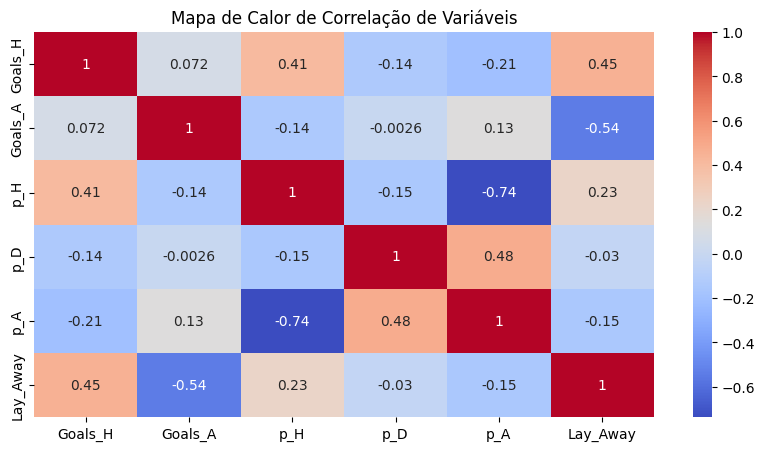

In [50]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize= (10,5))
sns.heatmap(correlacao, annot=True, cmap='coolwarm')
plt.title("Mapa de Calor de Correlação de Variáveis")
plt.show()


In [51]:
df.columns.to_list()

['Date',
 'Time',
 'League',
 'Home',
 'Away',
 'Goals_H',
 'Goals_A',
 'Goals_Min_H',
 'Goals_Min_A',
 'Odd_H',
 'Odd_H_Lay',
 'Odd_A',
 'Odd_A_Lay',
 'Odd_D',
 'Odd_D_Lay',
 'Odd_Over25',
 'Odd_Over25_FT_Lay',
 'Odd_Under25',
 'Odd_Under25_FT_Lay',
 'Odd_BTTS_Yes',
 'Odd_BTTS_Yes_Lay',
 'Odd_BTTS_No',
 'Odd_BTTS_No_Lay',
 'Odd_CS_0x0_Back',
 'Odd_0x0',
 'Odd_CS_0x1_Back',
 'Odd_0x1',
 'Odd_CS_1x0_Back',
 'Odd_1x0',
 'p_H',
 'p_D',
 'p_A',
 'p_Over',
 'p_Under',
 'p_BTTS_Y',
 'p_BTTS_N',
 'p_0x0',
 'p_0x1',
 'p_1x0',
 'CV_Odds_MO',
 'Media_Ptos_H',
 'Media_Ptos_A',
 'DesvPad_Ptos_H',
 'DesvPad_Ptos_A',
 'CV_Ptos_H',
 'CV_Ptos_A',
 'Media_GM_H',
 'Media_GM_A',
 'DesvPad_GM_H',
 'DesvPad_GM_A',
 'CV_GM_H',
 'CV_GM_A',
 'Media_GS_H',
 'Media_GS_A',
 'DesvPad_GS_H',
 'DesvPad_GS_A',
 'CV_GS_H',
 'CV_GS_A',
 'Media_SG_H',
 'Media_SG_A',
 'DesvPad_SG_H',
 'DesvPad_SG_A',
 'CV_SG_H',
 'CV_SG_A',
 'Media_SG_H_01',
 'Media_SG_A_01',
 'DesvPad_SG_H_01',
 'DesvPad_SG_A_01',
 'CV_SG_H_01',
 'CV_S

In [53]:
features = ['p_H','p_D','p_A','p_Over','p_Under','p_BTTS_Y','p_BTTS_N','CV_Odds_MO',
'Media_Ptos_H','Media_Ptos_A','DesvPad_Ptos_H','DesvPad_Ptos_A','CV_Ptos_H','CV_Ptos_A',
'Media_GM_H','Media_GM_A','DesvPad_GM_H','DesvPad_GM_A','CV_GM_H','CV_GM_A',
'Media_GS_H','Media_GS_A','DesvPad_GS_H','DesvPad_GS_A','CV_GS_H','CV_GS_A',
'Media_SG_H','Media_SG_A','DesvPad_SG_H','DesvPad_SG_A','CV_SG_H','CV_SG_A',
'Media_SG_H_01','Media_SG_A_01','DesvPad_SG_H_01','DesvPad_SG_A_01','CV_SG_H_01','CV_SG_A_01',
'Media_SG_H_02','Media_SG_A_02','DesvPad_SG_H_02','DesvPad_SG_A_02','CV_SG_H_02','CV_SG_A_02',
'Media_VG_H','Media_VG_A','DesvPad_VG_H','DesvPad_VG_A','CV_VG_H','CV_VG_A',
'Media_CG_H_00','Media_CG_A_00','DesvPad_CG_H_00','DesvPad_CG_A_00','CV_CG_H_00','CV_CG_A_00',
'Media_CG_H_01','Media_CG_A_01','DesvPad_CG_H_01','DesvPad_CG_A_01','CV_CG_H_01','CV_CG_A_01',
'Media_CG_H_02','Media_CG_A_02','DesvPad_CG_H_02','DesvPad_CG_A_02','CV_CG_H_02','CV_CG_A_02',
'VAR01',
 'VAR02',
 'VAR03',
 'VAR04',
 'VAR05',
 'VAR06',
 'VAR07',
 'VAR08',
 'VAR09',
 'VAR10',
 'VAR11',
 'VAR12',
 'VAR13',
 'VAR14',
 'VAR15',
 'VAR16',
 'VAR17',
 'VAR18',
 'VAR19',
 'VAR20',
 'VAR21',
 'VAR22',
 'VAR23',
 'VAR24',
 'VAR25',
 'VAR26',
 'VAR27',
 'VAR28',
 'VAR29',
 'VAR30',
 'VAR31',
 'VAR32',
 'VAR33',
 'VAR34',
 'VAR35',
 'VAR36',
 'VAR37',
 'VAR38',
 'VAR39',
 'VAR40',
 'VAR41',
 'VAR42',
 'VAR43',
 'VAR44',
 'VAR45',
 'VAR46',
 'VAR47',
 'VAR48',
 'VAR49',
 'VAR50',
 'VAR51',
 'VAR52',
 'VAR53',
 'VAR54',
 'VAR55',
 'VAR56',
 'VAR57',
 'VAR58',
 'VAR59',
 'VAR60',
 'VAR61',
 'VAR62',
 'VAR63',
 'VAR64',
 'VAR65',
 'VAR66',
 'VAR67',
 'VAR68',
 'VAR69',
 'VAR70',
 'VAR71',
 'VAR72',
 'VAR73',
 'VAR74',
 'VAR75',
 'VAR76',
 'VAR77',
'Lay0x1']

In [54]:
df0 = df[features]
df0

,p_H,p_D,p_A,p_Over,p_Under,p_BTTS_Y,p_BTTS_N,CV_Odds_MO,Media_Ptos_H,Media_Ptos_A,DesvPad_Ptos_H,DesvPad_Ptos_A,CV_Ptos_H,CV_Ptos_A,Media_GM_H,Media_GM_A,DesvPad_GM_H,DesvPad_GM_A,CV_GM_H,CV_GM_A,Media_GS_H,Media_GS_A,DesvPad_GS_H,DesvPad_GS_A,CV_GS_H,CV_GS_A,Media_SG_H,Media_SG_A,DesvPad_SG_H,DesvPad_SG_A,CV_SG_H,CV_SG_A,Media_SG_H_01,Media_SG_A_01,DesvPad_SG_H_01,DesvPad_SG_A_01,CV_SG_H_01,CV_SG_A_01,Media_SG_H_02,Media_SG_A_02,DesvPad_SG_H_02,DesvPad_SG_A_02,CV_SG_H_02,CV_SG_A_02,Media_VG_H,Media_VG_A,DesvPad_VG_H,DesvPad_VG_A,CV_VG_H,CV_VG_A,Media_CG_H_00,Media_CG_A_00,DesvPad_CG_H_00,DesvPad_CG_A_00,CV_CG_H_00,CV_CG_A_00,Media_CG_H_01,Media_CG_A_01,DesvPad_CG_H_01,DesvPad_CG_A_01,CV_CG_H_01,CV_CG_A_01,Media_CG_H_02,Media_CG_A_02,DesvPad_CG_H_02,DesvPad_CG_A_02,CV_CG_H_02,CV_CG_A_02,VAR01,VAR02,VAR03,VAR04,VAR05,VAR06,VAR07,VAR08,VAR09,VAR10,VAR11,VAR12,VAR13,VAR14,VAR15,VAR16,VAR17,VAR18,VAR19,VAR20,VAR21,VAR22,VAR23,VAR24,VAR25,VAR26,VAR27,VAR28,VAR29,VAR30,VAR31,VAR32,VAR33,VAR34,VAR35,VAR36,VAR37,VAR38,VAR39,VAR40,VAR41,VAR42,VAR43,VAR44,VAR45,VAR46,VAR47,VAR48,VAR49,VAR50,VAR51,VAR52,VAR53,VAR54,VAR55,VAR56,VAR57,VAR58,VAR59,VAR60,VAR61,VAR62,VAR63,VAR64,VAR65,VAR66,VAR67,VAR68,VAR69,VAR70,VAR71,VAR72,VAR73,VAR74,VAR75,VAR76,VAR77,Lay0x1
1,0.259740,0.270270,0.495050,0.558659,0.495050,0.568182,0.454545,0.389013,1.6,2.0,1.341641,1.414214,0.838525,0.707107,2.0,2.0,0.707107,2.345208,0.353553,1.172604,1.4,0.4,0.894427,0.547723,0.638877,1.369306,0.6,1.6,1.516575,2.701851,2.527625,1.688657,1.480,4.532,3.627203,7.264617,2.450813,1.602960,1.788,4.064,3.825631,5.389685,2.139615,1.326202,0.812055,0.842173,0.200876,0.974617,0.247367,1.157264,0.183119,0.394695,0.066377,0.333351,0.362479,0.844579,6.058,5.908,1.700781,6.320628,0.280750,1.069842,1.165683,1.178096,0.331605,1.044882,0.284472,0.886925,0.961039,0.524675,1.040541,0.545946,1.905941,1.831683,1.128492,0.886139,1.250000,0.800000,0.464935,0.483784,0.886139,0.524675,0.545946,1.000000,0.457143,0.475676,0.871287,0.571429,0.594595,1.089109,0.240625,0.231250,0.126250,0.111875,0.126250,0.110000,0.137500,0.366667,0.352381,0.192381,0.170476,0.192381,0.167619,0.209524,0.233333,0.224242,0.122424,0.108485,0.122424,0.106667,0.133333,0.656250,1.031250,1.523810,1.571429,0.969697,0.636364,0.260056,0.060367,0.111111,0.189645,0.235309,0.010530,0.224779,0.063610,0.113636,0.032738,0.001894,0.034632,6.710264,0.301660,6.412541,-1.821670,-3.251946,0.937794,-0.054257,-0.992036,0.475325,0.038961,0.454054,0.128492,0.250000,0.343750,0.031250,0.571429,1
2,0.181818,0.277778,0.588235,0.438596,0.595238,0.471698,0.581395,0.608208,1.4,2.2,1.516575,1.095445,1.083268,0.497930,1.6,1.6,0.547723,1.516575,0.342327,0.947859,1.6,0.4,1.516575,0.547723,0.947859,1.369306,0.0,1.2,1.581139,1.303840,1.000000,1.086534,-0.194,1.810,4.406049,1.688100,-22.711591,0.932652,0.028,12.360,3.368029,16.754414,120.286732,1.355535,0.660055,0.223749,0.249795,0.147496,0.378445,0.659206,0.265796,0.537124,0.131320,0.288395,0.494064,0.536925,4.732,2.420,1.995138,1.785979,0.421627,0.738008,0.980972,1.111801,0.220146,0.711387,0.224416,0.639851,0.654545,0.309091,1.527778,0.472222,3.235294,2.117647,0.736842,1.357143,0.811321,1.232558,0.414545,0.633333,1.341176,0.305455,0.466667,0.988235,0.385455,0.588889,1.247059,0.312727,0.477778,1.011765,0.005612,0.003673,0.001735,0.002327,0.001714,0.002163,0.001755,0.005612,0.003673,0.001735,0.002327,0.001714,0.002163,0.001755,0.005612,0.003673,0.001735,0.002327,0.001714,0.002163,0.001755,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.430929,0.151515,0.104167,0.000000,0.406417,0.095960,0.310458,0.156642,0.109697,0.000000,0.000000,0.000000,11.486589,2.746933,8.823532,4.478309,3.139449,0.000000,0.000000,0.000000,0.690909,0.345455,0.527778,0.263158,0.188679,0.000000,0.000000,0.000000,1
3,0.523560,0.294118,0.227273,0.462963,0.584795,0.526316,0.552486,0.446151,1.6,0.6,1.341641,0.547723,0.838525,0.912871,0.8,0.8,0.836660,0.836660,1.045825,1.045825,0.6,1.6,0.894427,0.894427,1.490712,0.559017,0.2,-0.8,1.4

In [55]:
correlacao = df0.corr()

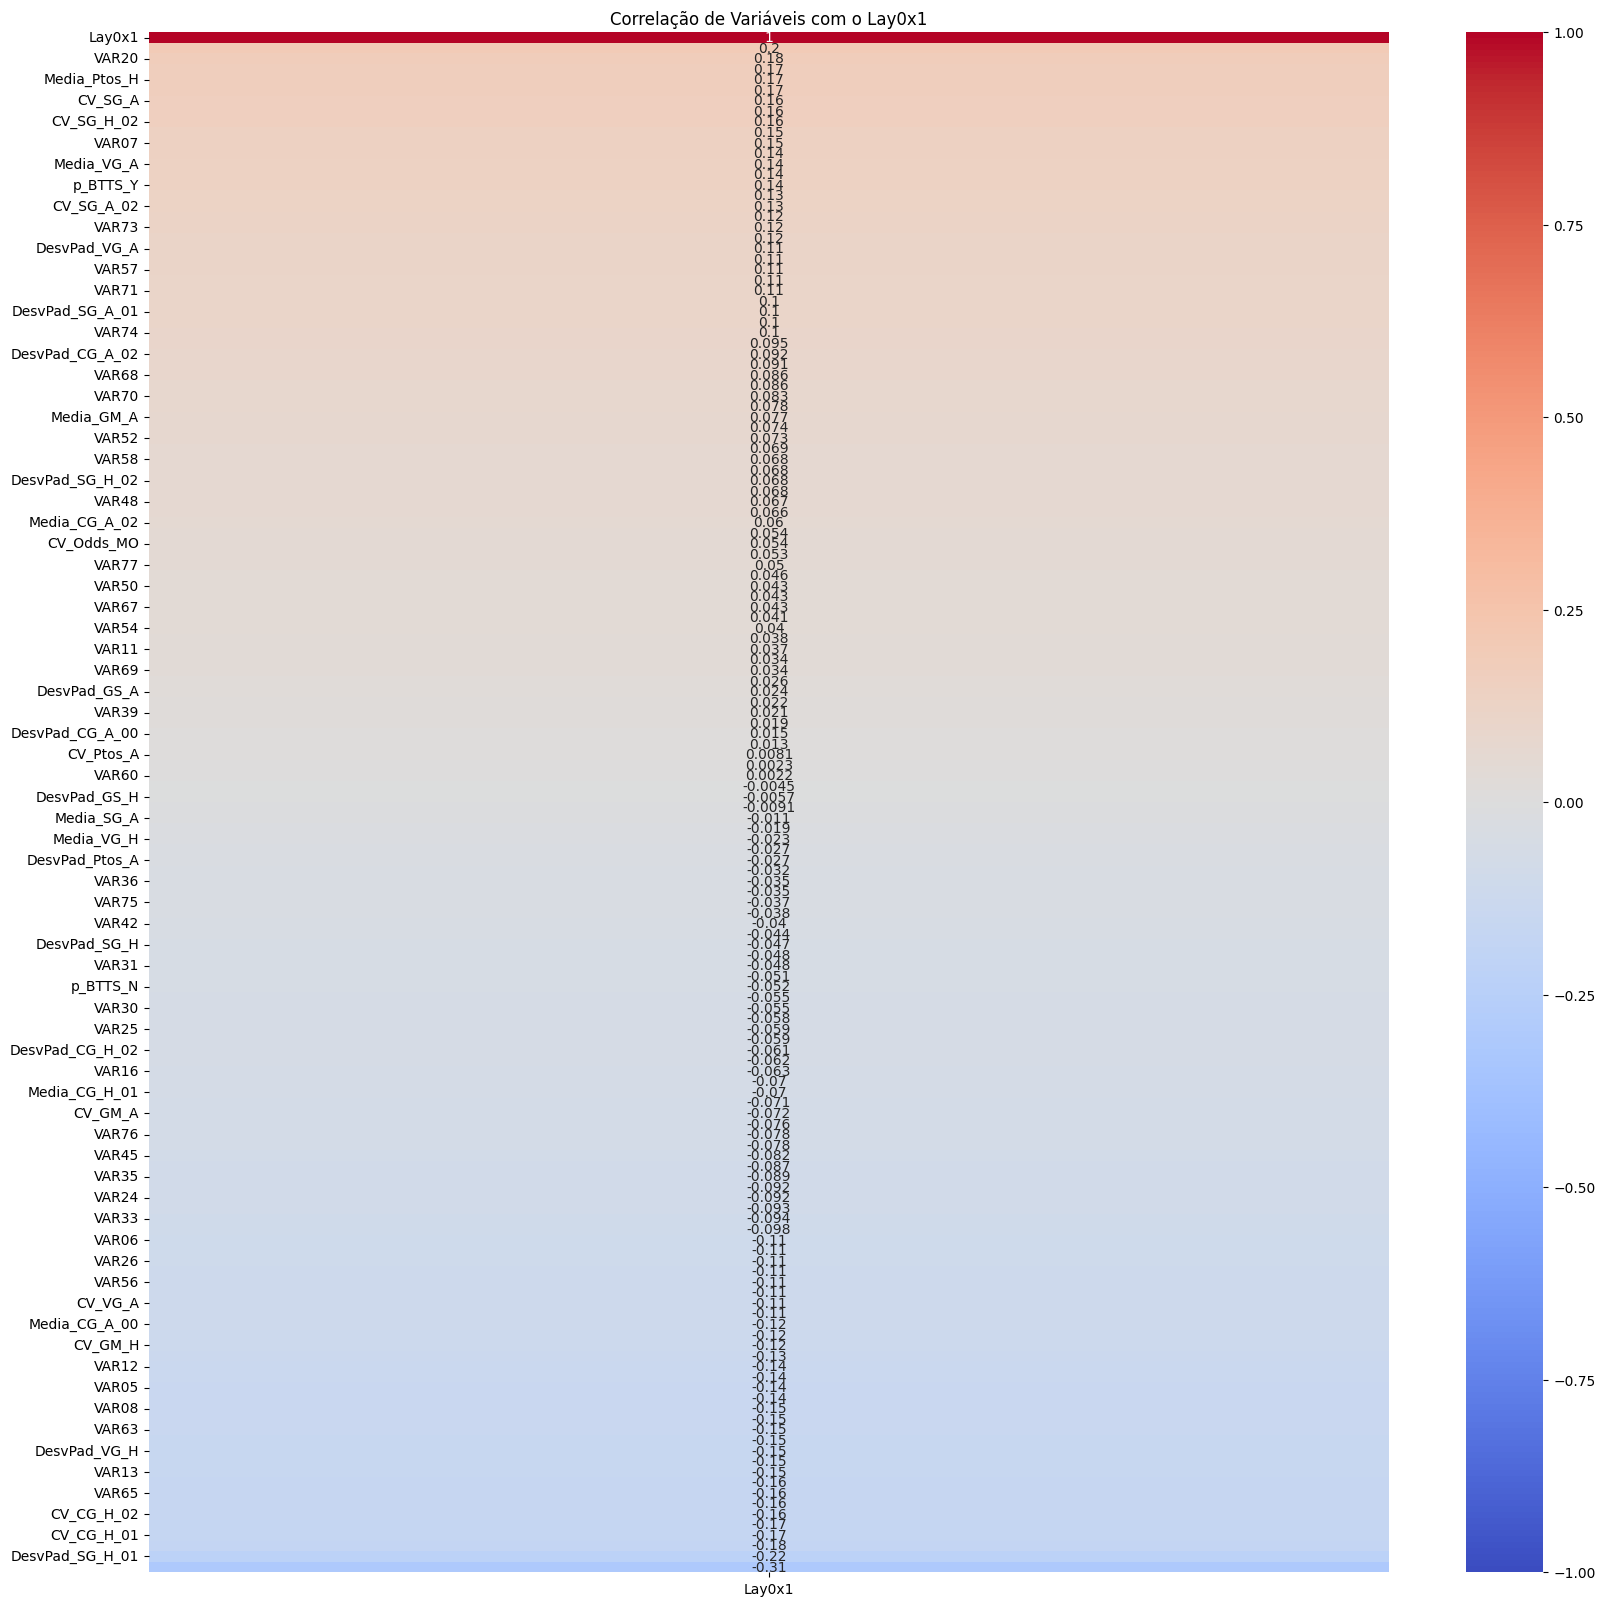

In [56]:
plt.figure(figsize= (20,20))

sns.heatmap(correlacao[['Lay0x1']].sort_values(by='Lay0x1', ascending=False),
            annot=True,
            cmap='coolwarm',
            vmin=-1,
            vmax=1)
plt.title("Correlação de Variáveis com o Lay0x1")
plt.show()